# CÀI ĐẶT THUẬT TOÁN

In [1]:
import numpy as np

class LinearRegressionNumpy:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        n_samples = X.shape[0]
        X_b = np.hstack([np.ones((n_samples, 1)), X])
        beta = np.dot(np.linalg.pinv(np.dot(X_b.T, X_b)), np.dot(X_b.T, y))
        self.b = beta[0]
        self.w = beta[1:]

    def predict(self, X):
        return np.dot(X, self.w) + self.b

def evaluate_regression(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0
    return mse, rmse, mae, r2

# TIỀN XỬ LÝ DỮ LIỆU

In [2]:
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5'] = df['Close'].rolling(5).mean()
df['MA20'] = df['Close'].rolling(20).mean()
df['Next_Close'] = df['Close'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'MA5', 'MA20', 'Vol_5d']
X = df[feature_cols].values
y = df['Next_Close'].values

split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (19826, 9), X_test shape: (4957, 9)


# HUẤN LUYỆN MÔ HÌNH

In [3]:
model = LinearRegressionNumpy()
model.fit(X_train, y_train)

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

mse_tr, rmse_tr, mae_tr, r2_tr = evaluate_regression(y_train, y_pred_train)
mse_te, rmse_te, mae_te, r2_te = evaluate_regression(y_test, y_pred_test)

print("=" * 60)
print("KẾT QUẢ ĐÁNH GIÁ (Bài 1 - Hồi quy Tuyến tính S&P 500 NumPy):")
print(f"- Train MSE  : {mse_tr:.4f} | Test MSE  : {mse_te:.4f}")
print(f"- Train RMSE : {rmse_tr:.4f} | Test RMSE : {rmse_te:.4f}")
print(f"- Train MAE  : {mae_tr:.4f} | Test MAE  : {mae_te:.4f}")
print(f"- Train R2   : {r2_tr:.4f} | Test R2   : {r2_te:.4f}")
print("=" * 60)

KẾT QUẢ ĐÁNH GIÁ (Bài 1 - Hồi quy Tuyến tính S&P 500 NumPy):
- Train MSE  : 34.0649 | Test MSE  : 1562.3543
- Train RMSE : 5.8365 | Test RMSE : 39.5266
- Train MAE  : 2.2389 | Test MAE  : 25.6059
- Train R2   : 0.9998 | Test R2   : 0.9995


# VẼ ĐỒ THỊ

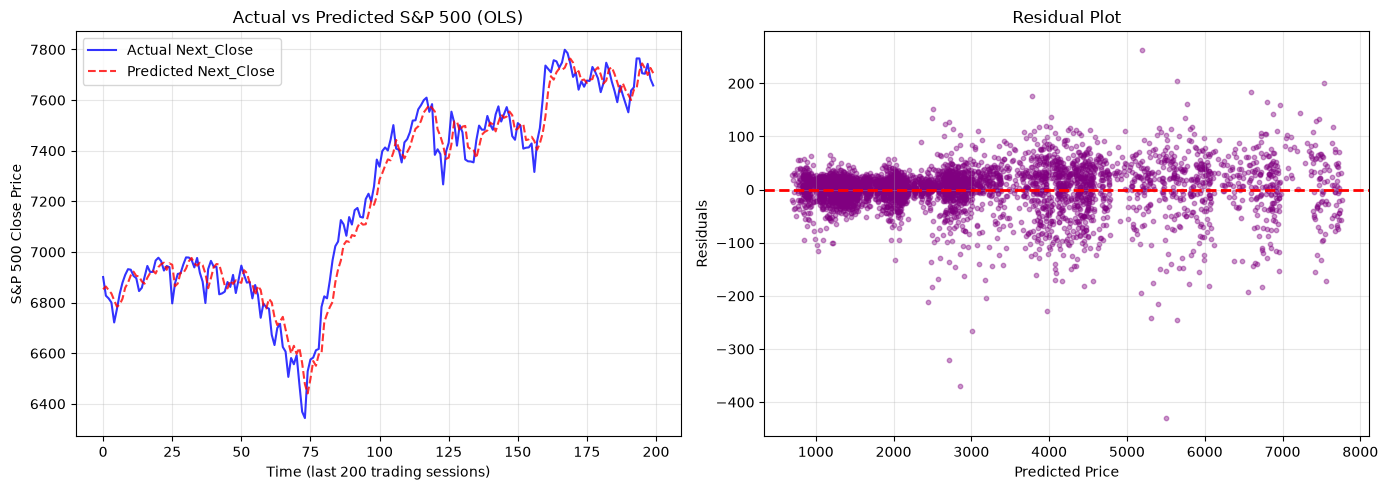

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(y_test[-200:], label="Actual Next_Close", color="blue", alpha=0.8)
axes[0].plot(y_pred_test[-200:], label="Predicted Next_Close", color="red", linestyle="--", alpha=0.8)
axes[0].set_xlabel("Time (last 200 trading sessions)")
axes[0].set_ylabel("S&P 500 Close Price")
axes[0].set_title("Actual vs Predicted S&P 500 (OLS)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

residuals = y_test - y_pred_test
axes[1].scatter(y_pred_test, residuals, alpha=0.4, color='purple', s=10)
axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residuals")
axes[1].set_title("Residual Plot")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()